# Módulo 1: Fundamentos, espacios de color y mejoramiento digital

## 1.2 Calidad, transformaciones de intensidad y filtrado espacial

Se parte de las imágenes guardadas en 1.1 (`frame0.png` y `roi_frame0.png`). Salvo el histograma del frame completo, todo se aplica sobre la ROI en escala de grises.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2

from modulos import modulo1_mejoramiento as m1
from modulos import metricas

INDICE_FRAME = 0

# Imágenes guardadas en 1.1
frame = cv2.imread(f"frame{INDICE_FRAME}.png")
roi = cv2.imread(f"roi_frame{INDICE_FRAME}.png")
if frame is None or roi is None:
    raise FileNotFoundError("No están las imágenes de 1.1: ejecutar antes analisis_modulo1.ipynb")

gris_frame = m1.a_gris(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
gris = m1.a_gris(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))   # imagen de trabajo de toda la sección

### Histograma en escala de grises

El histograma cuenta cuántos píxeles hay en cada nivel de gris. Se calcula para el frame completo y para la ROI.

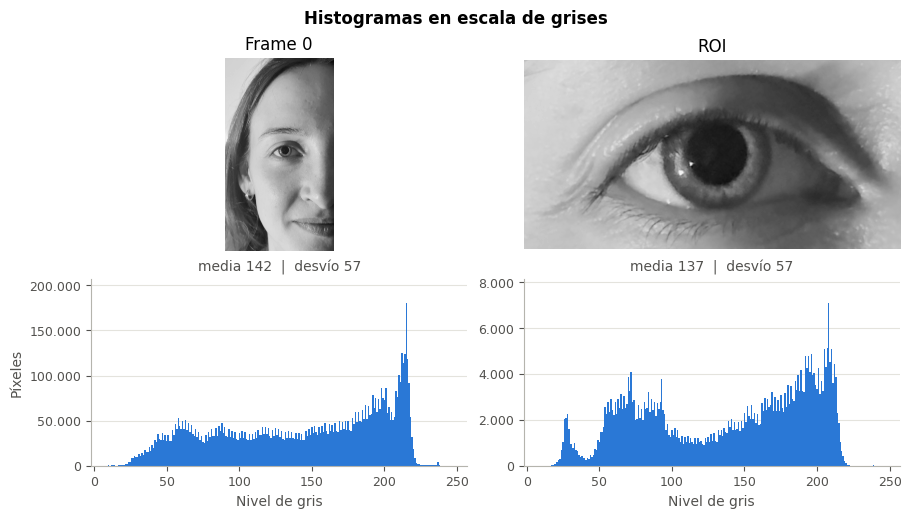

In [2]:
m1.mostrar_con_histogramas([gris_frame, gris], [f"Frame {INDICE_FRAME}", "ROI"], "Histogramas en escala de grises")

El histograma del frame completo cubre casi todo el rango. Nuestra hipótesis es que el pelo aporta la meseta en los niveles bajos, entre 40 y 70 aproximadamente; la piel clara ocupa los niveles intermedios y altos. Además, aparece un pico angosto cerca de 200, asociado a regiones claras y homogéneas como la piel más iluminada o la pared blanca de fondo. La pupila ocupa una fracción mínima del frame y no se distingue en este histograma.

El histograma de la ROI tiene tres partes bien definidas:

* un pico pequeño en torno a 25, que corresponde a la pupila y se extiende hasta 45;
* un grupo intermedio entre 50 y 110, formado por el iris y las sombras del pliegue y de la ojera;
* un grupo mayoritario entre 130 y 220, que viene dado por la piel y la esclerótica.

Al recortar la ROI se vuelve más notorio el rango de la pupila en el histograma. Por último, los valles entre estos grupos son la referencia que vamos a usar para elegir el rango de interés del escalado en el siguiente punto.

### Brillo y contraste

- **Brillo:** se modificó el brillo sumando una constante de +50: g = f + 50.
- **Contraste:** se modificó el contraste multiplicando por un factor 1,5: g = 1,5 · f.

En ambos casos los valores que exceden 255 se saturan en 255 para que el tipo `uint8` no dé la vuelta (y que no pasen cosas como 250 + 50 = 44, donde los píxeles más claros aparecerían oscuros).

,Media,Desvío,Mín,Máx,% en 0,% en 255,Niveles usados
Imagen,,,,,,,
Original,137.23,56.83,5,253,0.0,0.00,243
Brillo +50,186.68,56.13,55,255,0.0,11.65,195
"Contraste ×1,5",191.27,70.25,8,255,0.0,39.36,160


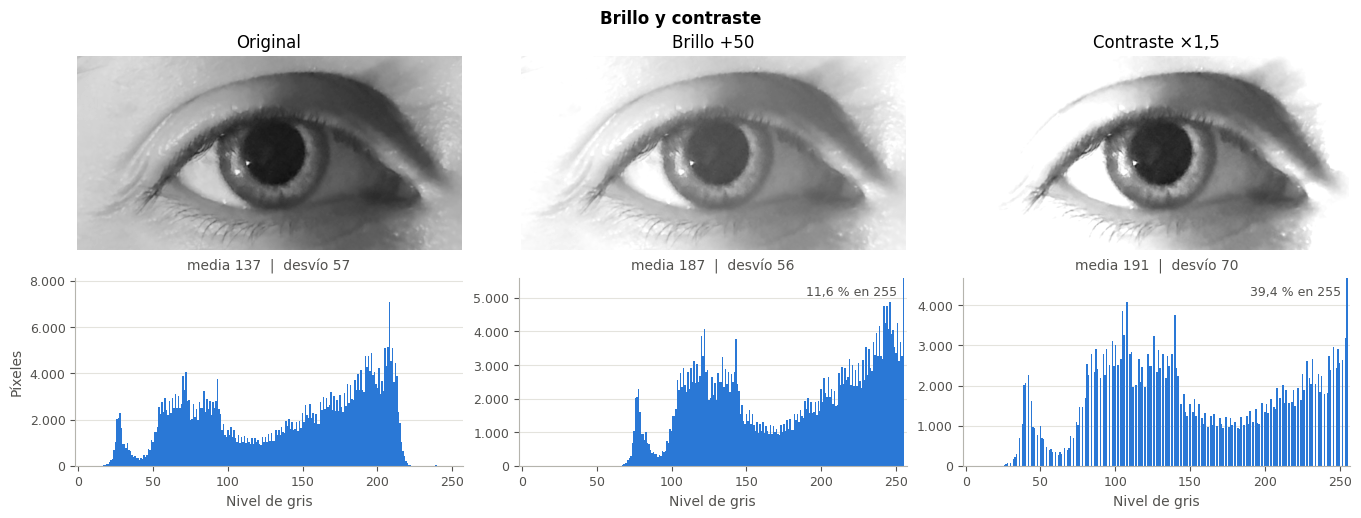

In [3]:
BRILLO = 50
CONTRASTE = 1.5

brillo = m1.ajustar_brillo(gris, BRILLO)
contraste = m1.ajustar_contraste(gris, CONTRASTE)

imagenes = [gris, brillo, contraste]
nombres = ["Original", f"Brillo +{BRILLO}", f"Contraste ×{m1.formato_decimal(CONTRASTE)}"]

display(m1.tabla_estadisticas(imagenes, nombres))
m1.mostrar_con_histogramas(imagenes, nombres, "Brillo y contraste")

Sumar 50 unidades al histograma lo desplaza 50 niveles hacia la derecha sin modificar su forma. La media pasa de 137,2 a 186,7 y el desvío se mantiene prácticamente igual (56,8 y 56,1), porque las diferencias entre píxeles no cambian. La imagen se ve más clara y la pupila deja de verse negra para pasar a un gris oscuro. En el extremo superior, los niveles iguales o mayores que 205 se saturan en 255, eso afecta al 11,7 % de los píxeles, principalmente piel y esclerótica. Por eso es que la media sube 49,4 y no 50, y la cantidad de niveles con distinto valor bajan de 243 a 195. En ese extremo hubo información que se perdió de forma irreversible.

Multiplicar por 1,5 produce una extensión del histograma, las distancias entre niveles crecen un 50 % y la distribución se estira hacia la derecha (ya que el factor de escalado es mayor a uno, por lo que todos los valores pueden únicamente aumentar en magnitud). Se observa que aumenta el contraste y se aclara la imagen (media 191,3). Uno de los efectos del estiramiento es que entre valores consecutivos queda un espacio de 1 o 2 unidades, por lo que casi un tercio de los niveles de salida quedan vacíos. La cantidad de niveles distintos no aumenta, sino que baja a 160, y se reparten en un rango mayor. El segundo efecto es la saturación: todos los valores mayores a 170 pasan a 255. Esto afecta a casi toda la piel y la esclerótica. Visualmente, la pupila, el iris y el pliegue palpebral ganan contraste, mientras que la piel y la esclerótica pierden toda su textura.

### Escalado por rango de interés

Transformación lineal por tramos: el intervalo [f₁, f₂] se estira a todo el rango [0, 255]; los niveles menores que f₁ pasan a 0 y los mayores que f₂, a 255.

g = 255 · (f − f₁) / (f₂ − f₁)

Para concentrar el contraste en la pupila y el iris, f₁ y f₂ se eligen a partir del histograma de la ROI, de modo que el intervalo cubra los niveles de ambas estructuras y deje afuera la piel y la esclerótica.

,Media,Desvío,Mín,Máx,% en 0,% en 255,Niveles usados
Imagen,,,,,,,
Original,137.23,56.83,5,253,0.0,0.00,243
"Escalado [15, 50]",248.54,30.60,0,255,0.0,94.81,36
"Escalado [15, 75]",238.37,43.94,0,255,0.0,79.84,61
"Escalado [15, 100]",222.60,56.77,0,255,0.0,66.04,86


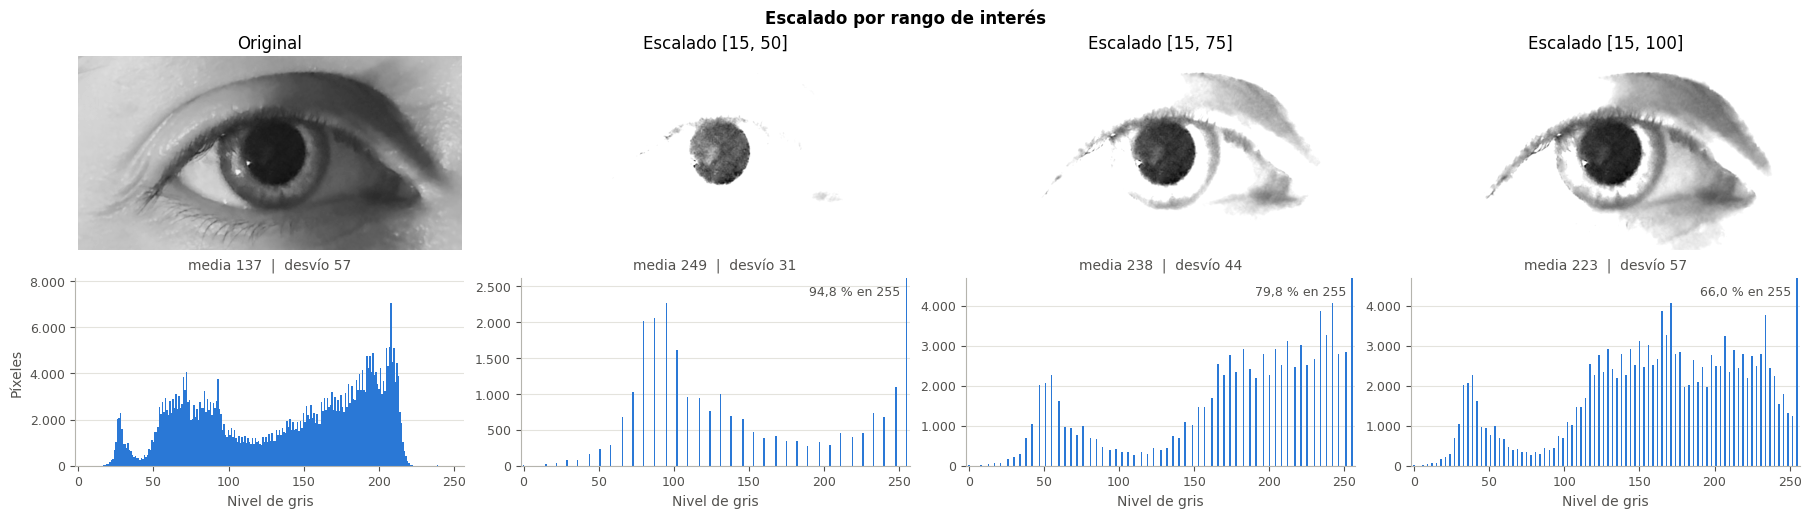

In [4]:
RANGOS = [(15, 50), (15, 75), (15, 100)]

escaladas = [m1.escalar_rango(gris, f1, f2) for f1, f2 in RANGOS]
nombres_escaladas = [f"Escalado [{f1}, {f2}]" for f1, f2 in RANGOS]

imagenes = [gris, *escaladas]
nombres = ["Original", *nombres_escaladas]

display(m1.tabla_estadisticas(imagenes, nombres))
m1.mostrar_con_histogramas(imagenes, nombres, "Escalado por rango de interés")

escalada, nombre_escalada = escaladas[-1], nombres_escaladas[-1]

El intervalo [f₁, f₂] se eligió manualmente a partir del histograma de la ROI. Se descartó un criterio automático basado en la posición de picos y valles, porque eso asume que la piel y la esclerótica forman un grupo más claro y separado del iris, y para los casos donde la piel no es clara, esto no se cumple en general.

El límite inferior se fijó en f₁ = 15, el extremo inferior del histograma, para que la pupila no se sature en negro. Para el límite superior se compararon tres valores:

f₂ = 50: abarca solo el pico de la pupila, hasta el valle cercano a 45.
f₂ = 75: agrega la parte más oscura del grupo intermedio.
f₂ = 100: incluye casi todo el iris.

Al aumentar f₂, baja la cantidad de píxeles saturados en 255 (94,8 %, 79,8 % y 66,0 %, respectivamente). Como más píxeles conservan niveles intermedios, la media desciende (249, 238 y 223) y el desvío aumenta (31, 44 y 57). En los tres casos quedan huecos en el histograma, que son más anchos cuanto menor es f₂.

Con [15, 50] la imagen queda reducida a la pupila sobre un fondo blanco, con algunos fragmentos de sombras de las pestañas. Este intervalo tiene implícitamente la hipótesis de que hay un umbral ubicado en el valle que separa la pupila del resto, lo que anticipa que la pupila podría llegar a aislarse por umbralización. Sin embargo, están muy estirados los niveles internos de la pupila, por lo que pierde su aspecto uniforme y se ve como una textura gris dominada por el ruido y los artefactos de compresión del video, mientras que el iris desaparece por completo.

Con [15, 75] la pupila vuelve a verse oscura, y su pico pasa a aproximadamente 55. Reaparecen el borde del iris, el pliegue del párpado y las pestañas, pero la mayor parte del iris sigue saturada en blanco.

Con [15, 100] el intervalo cubre casi todo el grupo intermedio. El iris recupera parte de sus niveles de gris, junto con las sombras del pliegue y de la ojera, y la pupila queda oscura y más homogénea, con su pico en torno a 40. Se decidió elegir [15, 100] para el análisis que sigue ya que mantiene un contraste pupila-iris máximo sin eliminar el iris, que es el contexto del borde que se busca medir. Los intervalos más chicos aumentan la ganancia sobre la pupila, pero esa ganancia se traduce en más ruido amplificado y en la pérdida de las estructuras que la rodean. El costo de esta opción es la saturación del 66 % de la imagen, que representan la piel, la esclerótica y las zonas más claras del iris, pero que de todos modos no aportan a la pupilometría.

### Ecualización del histograma: global y local (CLAHE)

**Global.** La función de transformación es la distribución acumulada (CDF) del histograma, normalizada a [0, 255]:

T(f) = 255 · (CDF(f) − CDF<sub>mín</sub>) / (N − CDF<sub>mín</sub>), con N la cantidad de píxeles.

Los niveles más frecuentes se separan entre sí y los poco frecuentes se agrupan, de modo que el histograma resultante tiende a ser uniforme.

**Local (CLAHE).** Aplica la misma idea en cada bloque de una grilla de 8 × 8. Antes de ecualizar, recorta el histograma de cada bloque a 2 veces su altura media, para no amplificar el ruido en zonas uniformes, y une los bloques interpolando.

Ambas se comparan con el escalado lineal del punto anterior.

,Media,Desvío,Mín,Máx,% en 0,% en 255,Niveles usados
Imagen,,,,,,,
Original,137.23,56.83,5,253,0.00,0.00,243
"Escalado [15, 100]",222.60,56.77,0,255,0.00,66.04,86
Ecualización global,128.33,73.83,0,255,0.15,0.22,171
CLAHE,139.22,57.87,2,254,0.00,0.00,251


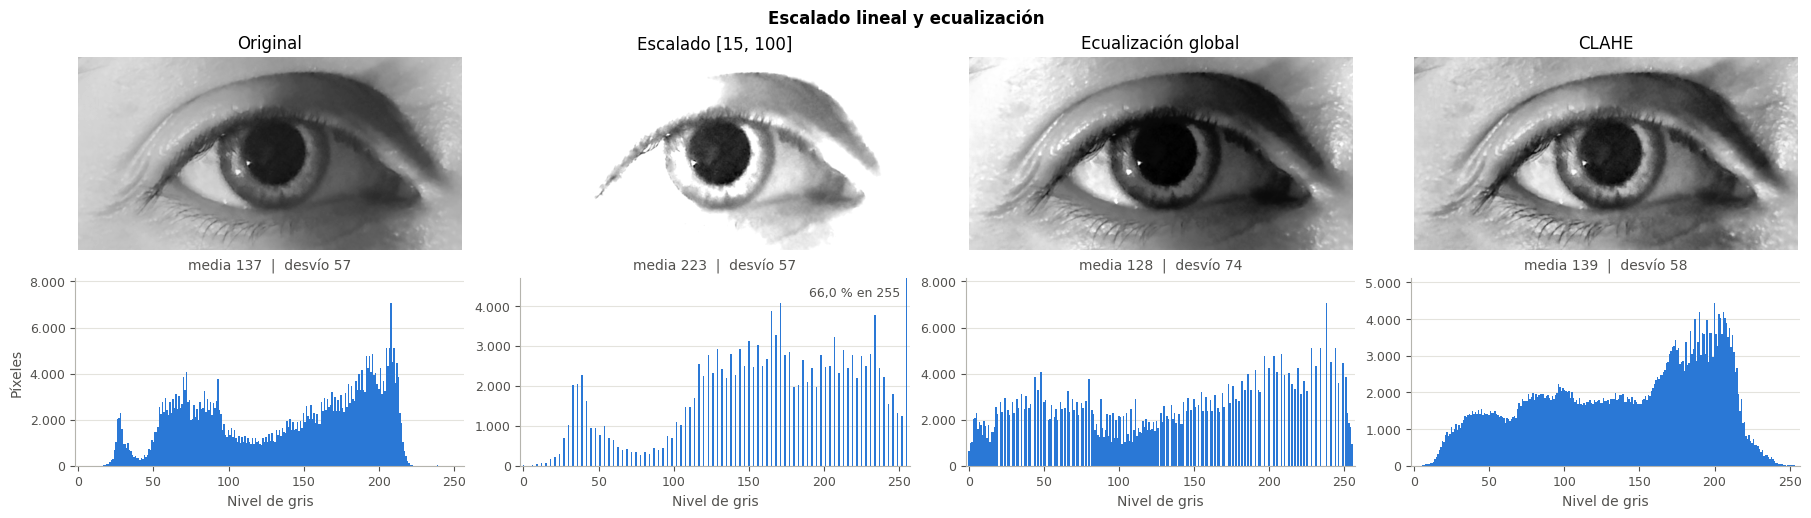

In [5]:
LIMITE_CLAHE = 2.0   # recorte del histograma de cada bloque
GRILLA_CLAHE = 8     # bloques por eje

eq_global = m1.ecualizar(gris)
eq_clahe = m1.ecualizar_clahe(gris, LIMITE_CLAHE, GRILLA_CLAHE)

imagenes = [gris, escalada, eq_global, eq_clahe]
nombres = ["Original", nombre_escalada, "Ecualización global", "CLAHE"]

display(m1.tabla_estadisticas(imagenes, nombres))
m1.mostrar_con_histogramas(imagenes, nombres, "Escalado lineal y ecualización")

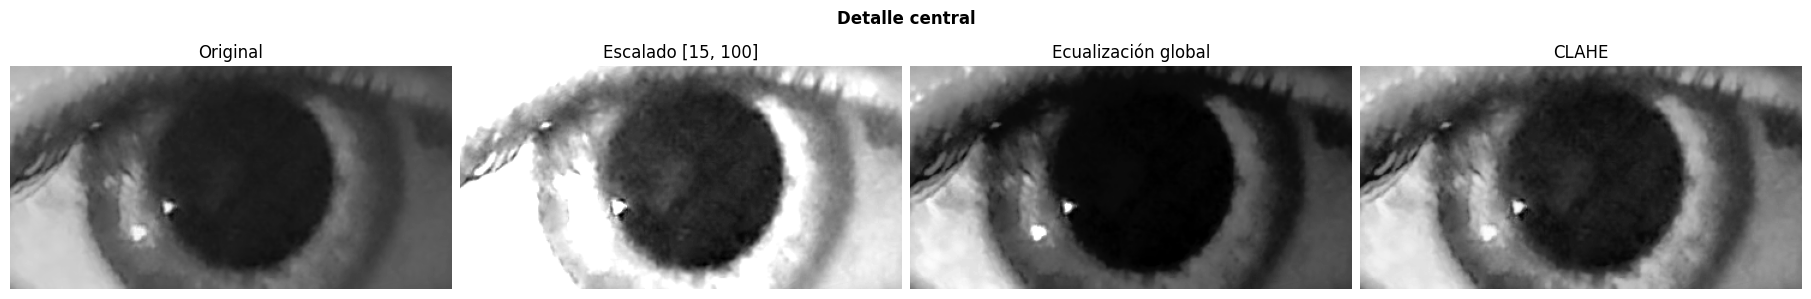

In [6]:
# Detalle central (pupila e iris) para evaluar artefactos
m1.mostrar_fila([m1.recorte_central(im) for im in imagenes], nombres, "Detalle central")

La ecualización global lleva el histograma a una distribución aproximadamente uniforme en todo el rango. La media pasa de 137 a 128, que es el centro del rango, y el desvío, de 57 a 74, que es el que tendría una distribución uniforme entre 0 y 255 (255/√12 ≈ 73,6). Cada grupo de la imagen recibe una porción del rango de salida que es proporcional a su cantidad de píxeles: la pupila representa una porción menor de la imagen, por lo que queda comprimida en los primeros pocos niveles de salida y se ve casi negra y sin detalle; los niveles mayores que 100 (piel, esclerótica y parte del iris), se reparten en más niveles.

Visualmente, observamos que en la ecualización global el contraste global aumenta, pero en regiones que no nos interesan. El histograma resultante no es exactamente plano, los niveles frecuentes quedan aislados y los poco frecuentes se fusionan; eso deja huecos y reduce los niveles distintos de 243 a 171. Como artefactos, la ecualización global amplifica la textura y el ruido de la piel, que se ve granulada, y oscurece notoriamente las sombras del pliegue y de la ojera.

La ecualización local (CLAHE) conserva el brillo y la dispersión de la original (media 139,2 y desvío 57,9, frente a 137,2 y 56,8) y no satura píxeles. Su histograma mantiene aproximadamente la forma del original, pero es más continuo y con los grupos menos separados. Por otro lado, la ecualización por bloques y la interpolación entre ellos generan valores nuevos: 251 niveles distintos, más que los 243 originales. Visualmente, se realza la textura del iris, las pestañas y el borde de la pupila sin saturar el brillo medio.

### Ruido y filtrado espacial

**Ruidos simulados**

- **Gaussiano:** aditivo, g = f + n, con n ~ N(0, σ²) y σ = 20 niveles. Modela el ruido térmico y electrónico del sensor.
- **Impulsivo (sal y pimienta):** el 5 % de los píxeles pasa a 0 o a 255. Modela píxeles defectuosos y errores de transmisión.
- **Speckle:** multiplicativo, g = f · (1 + n), con n ~ N(0, σ²) y σ = 0,2. Su amplitud crece con la intensidad, y aparece en sistemas de imágenes que usan luz láser, microondas o ultrasonido, como las ecografías.

**Filtros (ventana de 5 × 5)**

- **Media:** promedio de la ventana.
- **Mediana:** valor central de la ventana ordenada de menor a mayor.
- **Gaussiano:** promedio ponderado por una gaussiana; con σ = 0, OpenCV lo calcula a partir del tamaño de la ventana.

La calidad se mide con PSNR (relación señal-ruido) y SSIM (Índice de Similitud Estructural, que compara la imagen procesada con la de referencia) respecto de la ROI original, sobre la imagen completa. La referencia ya contiene el ruido propio de la cámara. Las figuras muestran el detalle central, porque a tamaño completo el ruido no se distingue en pantalla. Se fijó una semilla para que el ruido sea el mismo en cada ejecución.

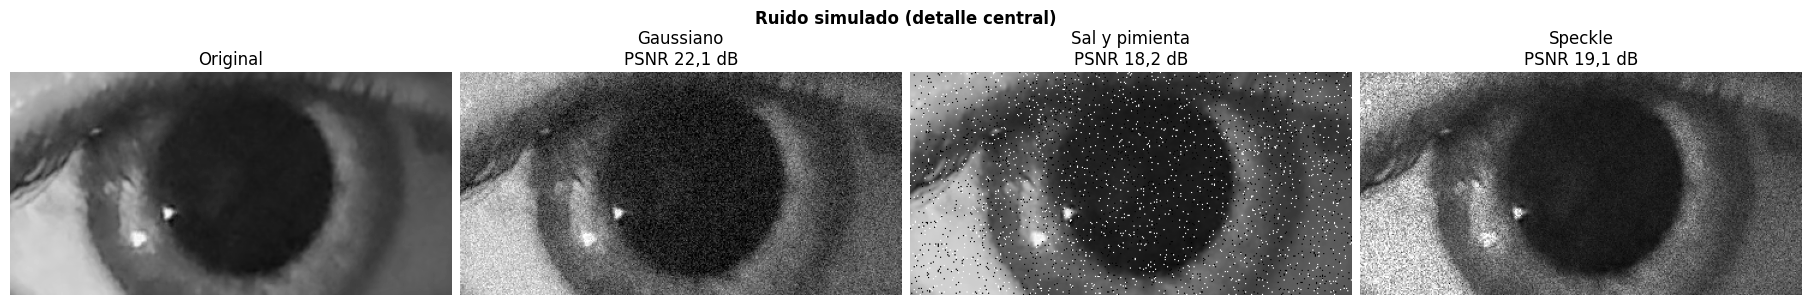

In [7]:
SEMILLA = 0
SIGMA_GAUSS = 20      # desvío, en niveles de gris
DENSIDAD_SP = 0.05    # fracción de píxeles afectados
SIGMA_SPECKLE = 0.2   # desvío relativo

rng = np.random.default_rng(SEMILLA)
ruidosas = {
    "Gaussiano": m1.ruido_gaussiano(gris, SIGMA_GAUSS, rng),
    "Sal y pimienta": m1.ruido_sal_pimienta(gris, DENSIDAD_SP, rng),
    "Speckle": m1.ruido_speckle(gris, SIGMA_SPECKLE, rng),
}

titulos = ["Original"] + [f"{nombre}\nPSNR {m1.formato_decimal(metricas.psnr(gris, im))} dB"
                          for nombre, im in ruidosas.items()]
m1.mostrar_fila([m1.recorte_central(im) for im in [gris, *ruidosas.values()]], titulos,
                "Ruido simulado (detalle central)")

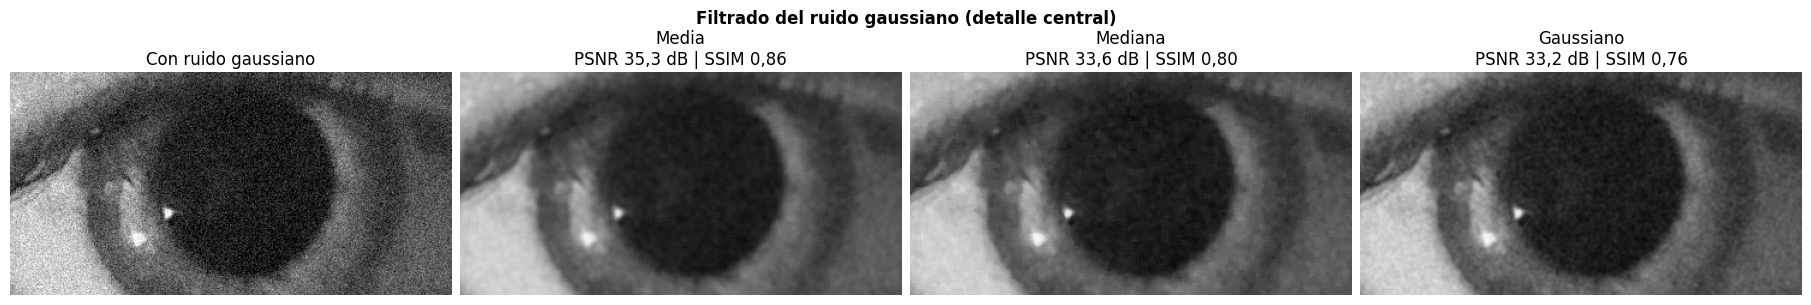

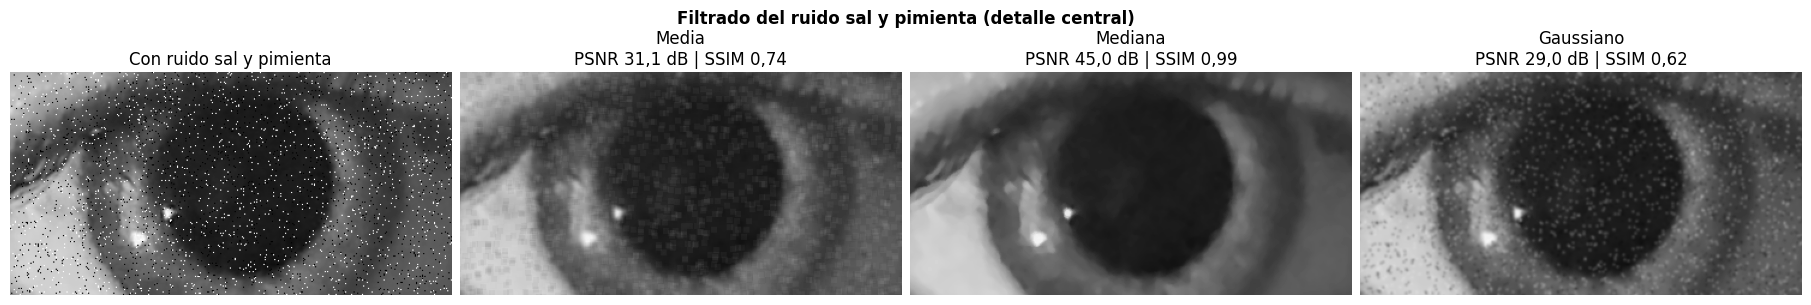

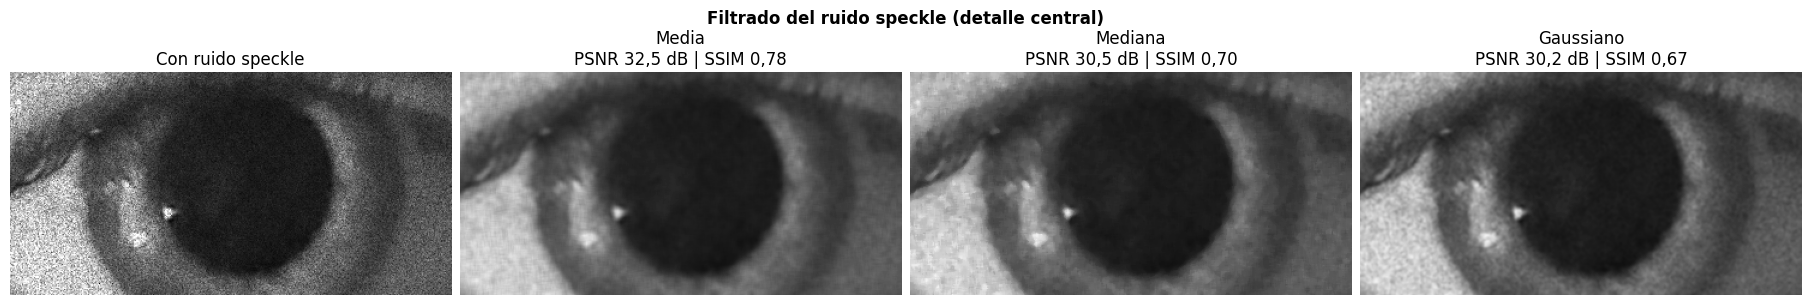

In [8]:
K = 5   # tamaño de la ventana (K x K)

FILTROS = {
    "Media": lambda im: cv2.blur(im, (K, K)),
    "Mediana": lambda im: cv2.medianBlur(im, K),
    "Gaussiano": lambda im: cv2.GaussianBlur(im, (K, K), 0),   # sigma a partir de K
}

filas = []
for nombre_ruido, ruidosa in ruidosas.items():
    imagenes = [ruidosa]
    titulos = [f"Con ruido {nombre_ruido.lower()}"]
    filas.append({"Ruido": nombre_ruido, "Filtro": "Sin filtrar",
                  "PSNR (dB)": metricas.psnr(gris, ruidosa), "SSIM": metricas.ssim(gris, ruidosa)})

    for nombre_filtro, filtrar in FILTROS.items():
        filtrada = filtrar(ruidosa)
        p, s = metricas.psnr(gris, filtrada), metricas.ssim(gris, filtrada)
        filas.append({"Ruido": nombre_ruido, "Filtro": nombre_filtro, "PSNR (dB)": p, "SSIM": s})
        imagenes.append(filtrada)
        titulos.append(f"{nombre_filtro}\nPSNR {m1.formato_decimal(p)} dB | SSIM {m1.formato_decimal(s, 2)}")

    m1.mostrar_fila([m1.recorte_central(im) for im in imagenes], titulos,
                    f"Filtrado del ruido {nombre_ruido.lower()} (detalle central)")

In [9]:
# Resumen: filas = ruido, columnas = filtro
resultados = pd.DataFrame(filas)
columnas = ["Sin filtrar", *FILTROS]

print("PSNR (dB)")
display(resultados.pivot(index="Ruido", columns="Filtro", values="PSNR (dB)")[columnas].round(2))
print("SSIM")
display(resultados.pivot(index="Ruido", columns="Filtro", values="SSIM")[columnas].round(3))

PSNR (dB)


Filtro,Sin filtrar,Media,Mediana,Gaussiano
Ruido,,,,
Gaussiano,22.14,35.30,33.63,33.20
Sal y pimienta,18.21,31.08,44.97,28.97
Speckle,19.08,32.51,30.49,30.18


SSIM


Filtro,Sin filtrar,Media,Mediana,Gaussiano
Ruido,,,,
Gaussiano,0.191,0.858,0.796,0.761
Sal y pimienta,0.216,0.739,0.989,0.616
Speckle,0.182,0.782,0.699,0.665


El ruido gaussiano con σ = 20 da un PSNR de 22,1 dB, igual que el valor teórico 20·log₁₀(255/20) ≈ 22,1 dB. El ruido sal y pimienta al 5 % y el speckle con σ = 0,2 degradan más la imagen (PSNR = 18,2 y 19,1 dB, respectivamente). En el speckle, el desvío del ruido es proporcional a la intensidad. En la piel y la esclerótica, con niveles cercanos a 200, alcanza unos 40 niveles, el doble que el gaussiano; en la pupila es mucho menor. Por eso, en el detalle se ve la pupila casi limpia, y las regiones claras muy granuladas. En los tres casos el SSIM cae entre 0,18 y 0,22.

Con ruido gaussiano, la media obtiene el mejor resultado (35,3 dB; SSIM 0,86), seguida por la mediana (33,6 dB; 0,80) y el filtro gaussiano (33,2 dB; 0,76):

Con ruido sal y pimienta, la mediana es la que mejor funcionó (45,0 dB; SSIM 0,99). Los impulsos son valores atípicos, 0 o 255, que la mediana descarta mientras ocupen menos de la mitad de la ventana.

Con speckle, la media vuelve a ser la mejor (32,5 dB; SSIM 0,78).



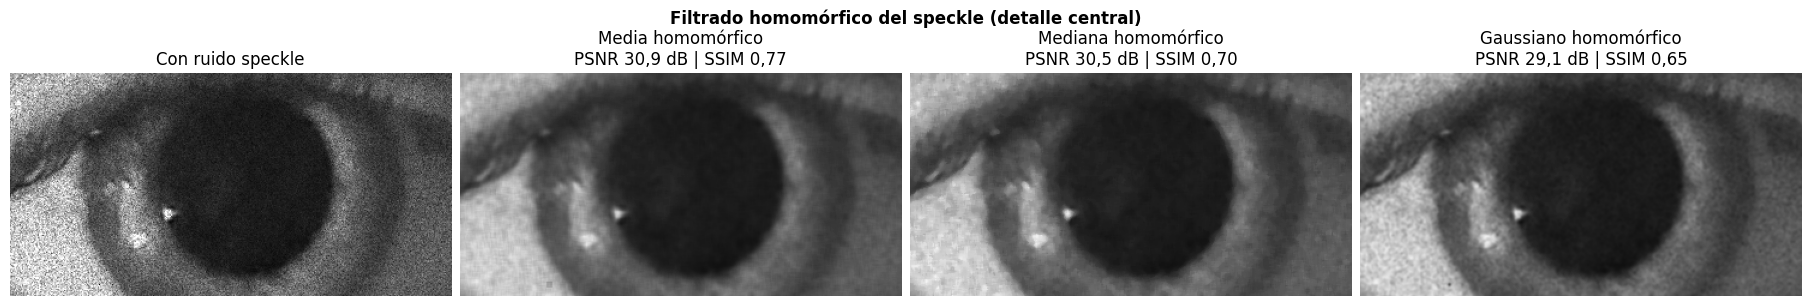

PSNR (dB)                SSIM            
Método      Directo Homomórfico Directo Homomórfico
Filtro                                             
Media        32.508      30.950   0.782       0.769
Mediana      30.492      30.492   0.699       0.699
Gaussiano    30.185      29.131   0.665       0.650

In [10]:
# Filtrado extra para el speckle: log → filtro → exp
speckle = ruidosas["Speckle"]
log_speckle = np.log1p(speckle.astype(np.float32))   # log(1 + g): evita log(0)

imagenes = [speckle]
titulos = ["Con ruido speckle"]
filas_homo = []

for nombre_filtro, filtrar in FILTROS.items():       # medianBlur en float admite solo K = 3 o 5
    directa = filtrar(speckle)
    homomorfica = np.expm1(filtrar(log_speckle))      # vuelta con exp(·) − 1
    homomorfica = np.clip(np.round(homomorfica), 0, 255).astype(np.uint8)

    for metodo, im in [("Directo", directa), ("Homomórfico", homomorfica)]:
        filas_homo.append({"Filtro": nombre_filtro, "Método": metodo,
                           "PSNR (dB)": metricas.psnr(gris, im), "SSIM": metricas.ssim(gris, im)})

    p, s = metricas.psnr(gris, homomorfica), metricas.ssim(gris, homomorfica)
    imagenes.append(homomorfica)
    titulos.append(f"{nombre_filtro} homomórfico\nPSNR {m1.formato_decimal(p)} dB | SSIM {m1.formato_decimal(s, 2)}")

m1.mostrar_fila([m1.recorte_central(im) for im in imagenes], titulos,
                "Filtrado homomórfico del speckle (detalle central)")

# Directo vs homomórfico, para cada filtro
tabla_homo = pd.DataFrame(filas_homo).pivot(index="Filtro", columns="Método", values=["PSNR (dB)", "SSIM"])
display(tabla_homo.loc[list(FILTROS)].round(3))

Otra cosa que probamos de hacer era aprovechar que el speckle es multiplicativo, g = f · (1 + n), y que al tomar logaritmos se transforma en un ruido aditivo: log g = log f + log(1 + n). Aplicamos los mismos filtros sobre la imagen logarítmica y luego volvimos al dominio original con la exponencial, para comparar contra el filtrado directo.

El resultado fue que este procedimiento no mejoró ningún resultado:

* Mediana: idéntica en ambos casos (30,49 dB; SSIM 0,699).
* Media: pasa de 32,51 a 30,95 dB (−1,56 dB) y de 0,782 a 0,769 de SSIM.
* Filtro gaussiano: pasa de 30,19 a 29,13 dB (−1,05 dB) y de 0,665 a 0,650 de SSIM.

Para el speckle simulado, el filtro de media directo sigue siendo la mejor opción (32,51 dB; SSIM 0,782).